# 10b — BES vs CAA on current models, protocol v2

Reruns notebook 10's comparison under a second protocol, fixed in advance in section 1, that widens the search for both methods, then applies that protocol unchanged to models it was never run on.

**What changes from notebook 10 (all choices are made on validation; the test questions are scored once per model):**

| | Notebook 10 (v1) | Notebook 10b (v2) |
|---|---|---|
| Prompt format check | none | letter mass and batch-padding check on fitting prompts and a separate MMLU dev slice, before anything is fitted |
| BES fitting items | 300 | the same 1,000 items CAA fits on |
| BES layers | 7-layer grid | grid plus the ±1 and ±2 neighbours of the best layer |
| BES question window | 16 tokens | 8, 16 or 32, chosen on validation |
| BES edited span | question tokens | question tokens or all tokens, chosen on validation (as in notebooks 02 and 07) |
| BES estimator | centred SVD | centred SVD, mean difference or LEACE, chosen on validation (notebook 02's estimator ablation) |
| BES ranks | 1–256 | 1–512 plus the cap (a quarter of the hidden size) |
| Learned eraser layer | the SVD layer | the best of the top three screened layers, by a short training run |
| Learned eraser loss | KL on opinion prompts | the same plus a retain term: KL on the no-opinion prompts with the eraser applied everywhere |
| CAA layers | 7-layer grid | every layer BES saw, plus the ±1 and ±2 neighbours of CAA's own best layer |
| CAA multipliers | −0.5 to −32 (7 values) | −0.5 to −64 (10 values) |
| Extra test metric | — | KL on the no-opinion prompts with each method applied (collateral change where there is no opinion to remove) |
| Novelty check | notebook 01, Qwen2.5 only | largest cosine between the BES directions and the CAA vector at the same layer, every model |

Selection rule, CAA matching, splits, MMLU and the factual control are unchanged from notebook 10. The training-free BES pick (SVD, mean difference or LEACE) is the algorithm as proposed; the learned eraser is trained with the model frozen and reported as a variant, as in notebook 09.

**How this run was produced.** Qwen2.5-1.5B, Qwen3.5-2B, Llama-3.2-3B, Llama-3.1-8B and Qwen3.5-9B ran on a Colab A100; after that session ended, Llama-2-7B ran on a local RTX 5080 with the five finished results copied in (hence cell 5's message), and each cell's output comes unchanged from one of those runs (the Qwen3.5-9B figure is shown from its saved file because the A100 session ended before it displayed). Not run: Muse Glimmer 30B (optional, `RUN_MUSE = False`).

In [1]:
# Environment: on Colab clone the repo, install requirements and a recent transformers (Qwen3.5 support), mount Drive; then build the pairs

import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers", "accelerate"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "flash-linear-attention", "bitsandbytes"], check=False)  # Qwen3.5 kernels; 4-bit loading
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert "CHAT_TEMPLATE_KWARGS" in Path("src/bes.py").read_text(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [2]:
# Hugging Face login for the gated Llama weights (skipped in offline smoke tests)

if os.environ.get("BES_SMOKE") != "1":
    from huggingface_hub import login
    login()

## 1. Models and the frozen v2 protocol

Every setting below is fixed before any model is run; Part A reruns notebook 10's four models, Part B applies the same settings to new models, and Muse Glimmer stays off unless switched on.

In [3]:
# Models and the shared v2 protocol settings (reduced automatically in smoke tests)

import gc, json, time
import numpy as np
import pandas as pd
import torch
import transformers
from src import bes, experiment as E, plots, stats

SMOKE = os.environ.get("BES_SMOKE") == "1"
PART_A = [
    {"tag": "qwen25_1p5b", "name": "Qwen/Qwen2.5-1.5B-Instruct", "chat": False, "dtype": "fp32", "role": "original Qwen (raw format, fp32, as in notebooks 02–05)"},
    {"tag": "qwen35_2b", "name": "Qwen/Qwen3.5-2B", "chat": True, "role": "current Qwen, closest in size to the original"},
    {"tag": "llama32_3b", "name": "meta-llama/Llama-3.2-3B-Instruct", "chat": True, "role": "current small Llama"},
    {"tag": "llama31_8b", "name": "meta-llama/Llama-3.1-8B-Instruct", "chat": True, "role": "current Llama at Llama-2-7B's size"},
]
PART_B = [
    {"tag": "qwen35_9b", "name": "Qwen/Qwen3.5-9B", "chat": True, "role": "current Qwen at Llama-3.1's size (not run in notebook 10)"},
    {"tag": "llama2_7b", "name": "meta-llama/Llama-2-7b-chat-hf", "chat": True, "role": "original Llama under protocol v2 (Anthropic splits, not Rimsky et al.'s items, so a protocol cross-check on notebooks 07–09)"},
]
MUSE = {"tag": "muse_glimmer_30b", "name": "meta-models/Muse-Glimmer-30B", "chat": True, "quant": "auto",
        "role": "current Meta open model (not a Llama); 4-bit unless the GPU has ~80 GB"}
RUN_MUSE = False              # optional: Muse Glimmer 30B is skipped unless this is True
REDO = False                  # False: skip a model whose v2 results are already saved
if SMOKE:
    PART_A = [{"tag": "smoke_raw", "name": os.environ["BES_MODEL"], "chat": False, "role": "smoke"},
              {"tag": "smoke_chat", "name": os.environ["BES_MODEL"], "chat": True, "role": "smoke"}]
    PART_B = []

bes.CHAT_TEMPLATE_KWARGS.update({"enable_thinking": False,      # Qwen3.5: answer directly, no reasoning block
                                 "date_string": "26 Jul 2024"})  # Llama-3.1: fixed date in its system header
V = "m10b"                                       # prefix of every v2 output file (v1 files are m10_*)
LAYER_FRACS = np.arange(0.25, 0.95, 0.1)         # notebook 10's layer grid, as fractions of depth
NEIGHBORS = (-2, -1, 1, 2)                       # refinement around the best layer (BES and CAA alike)
SCREEN_RANKS = (4, 16, 64)                       # ranks tried at every screened layer and window
WINDOWS = (8, 16, 32) if not SMOKE else (2, 4)   # question-window lengths for fitting BES directions
BES_SPANS = ("question", "all")                  # where BES edits (notebook 02: question won on Qwen; notebook 07: all won on Llama-2)
W0 = 16 if not SMOKE else 4                      # window used for the layer screen (notebook 10's value)
RANKS = (1, 2, 4, 8, 16, 32, 64, 128, 256, 512)  # full sweep at the chosen layer, plus the rank cap
STRENGTHS = (0.5, 0.75, 1.0)
LEARN_K = (4, 16)                                # learned erasers
LEARN_STEPS, LEARN_BS, LEARN_LR = (450, 4, 2e-3) if not SMOKE else (6, 4, 2e-3)
LEARN_SCREEN_STEPS = 150 if not SMOKE else 4     # short run used to choose the learned eraser's layer
LEARN_SCREEN_LAYERS = 3
RETAIN_WEIGHT = 1.0                              # weight of the no-opinion retain term (fixed, not tuned)
ALPHAS = (-0.5, -1.0, -2.0, -4.0, -8.0, -16.0, -24.0, -32.0, -48.0, -64.0)
CAA_SPANS = ("last", "question", "all")
MIN_DROP = 0.03                                  # a setting must lower validation sycophancy by this much to count
N_MMLU, N_FACT, N_DEV = (1000, 500, 200) if not SMOKE else (40, 40, 16)
N_CHECK = 64 if not SMOKE else 8                 # prompts per format check
PAD_TOL = 0.01                                   # max mean change in answer probabilities allowed from batch padding
PAD_AGREE = 0.95                                 # min share of prompts whose top answer is unchanged by batch padding
MASS_MIN = 0.5                                   # minimum next-token probability on the answer letters
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0.0
SMALL_GPU = 0 < GPU_GB < 24                      # e.g. a 16 GB card: smaller batches, one prompt per learned-eraser step (same results, less memory)
print("transformers", transformers.__version__, "| Qwen3.5 support:", hasattr(transformers, "Qwen3_5ForCausalLM"))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none", f"({GPU_GB:.0f} GB{', memory-saving mode' if SMALL_GPU else ''})")
pd.DataFrame(PART_A + PART_B + [MUSE | {"optional": True}])

transformers 5.23.0 | Qwen3.5 support: True
GPU: NVIDIA A100-SXM4-80GB


,tag,name,chat,dtype,role,quant,optional
0,qwen25_1p5b,Qwen/Qwen2.5-1.5B-Instruct,False,fp32,"original Qwen (raw format, fp32, as in noteboo...",NaN,NaN
1,qwen35_2b,Qwen/Qwen3.5-2B,True,NaN,"current Qwen, closest in size to the original",NaN,NaN
2,llama32_3b,meta-llama/Llama-3.2-3B-Instruct,True,NaN,current small Llama,NaN,NaN
3,llama31_8b,meta-llama/Llama-3.1-8B-Instruct,True,NaN,current Llama at Llama-2-7B's size,NaN,NaN
4,qwen35_9b,Qwen/Qwen3.5-9B,True,NaN,current Qwen at Llama-3.1's size (not run in n...,NaN,NaN
5,llama2_7b,meta-llama/Llama-2-7b-chat-hf,True,NaN,original Llama under protocol v2 (Anthropic sp...,NaN,NaN
6,muse_glimmer_30b,meta-models/Muse-Glimmer-30B,True,NaN,current Meta open model (not a Llama); 4-bit u...,auto,True


In [4]:
# Resume after a disconnect: copy v2 results already saved to Drive back into results/, so finished models are skipped

import shutil
restored = []
if E.DRIVE_DIR.exists() and not SMOKE:
    E.RESULTS.mkdir(exist_ok=True)
    for f in [*E.DRIVE_DIR.glob(f"{V}_*"), *E.DRIVE_DIR.glob(f"fig_{V}_*"), *E.DRIVE_DIR.glob("m10_summary.csv")]:
        if not (E.RESULTS / f.name).exists():
            shutil.copy(f, E.RESULTS / f.name)
            restored.append(f.name)
done = sorted(p.name.split("_test")[0][len(V) + 1:] for p in E.RESULTS.glob(f"{V}_*_test.csv"))
print(f"restored {len(restored)} files from Drive | models already finished (will be skipped): {done or 'none'}")

restored 0 files from Drive | models already finished (will be skipped): ['llama31_8b', 'llama32_3b', 'qwen25_1p5b', 'qwen35_2b', 'qwen35_9b']


## 2. Shared pieces

Scoring, selection, the prompt-format check, direction fitting, the learned eraser and CAA, written once and applied to every model.

In [5]:
# Scoring, selection and model loading

def summ(per):
    return {"syco": float(per["syco"].mean()), "kl": float(per["kl"].mean())}


def val_score(run, items, iv=None, span="all"):
    return summ(run.evaluate(items, iv, span)[1])


def best_by_j(df, base_syco):
    """Lowest sycophancy + KL among settings that lower sycophancy by MIN_DROP (all settings if none do)."""
    ok = df[df.syco <= base_syco - MIN_DROP]
    pool = ok if len(ok) else df
    return pool.assign(j=pool.syco + pool.kl).sort_values("j").iloc[0], bool(len(ok))


def load_runner(spec):
    dtype = spec.get("dtype") or ("bf16" if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else ("fp16" if torch.cuda.is_available() else "fp32"))
    quant = spec.get("quant")
    if quant == "auto":   # 4-bit on a 40 GB card, full bf16 on an 80 GB card
        big = torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 70e9
        quant = None if big else "4bit"
    big_gpu = torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 70e9
    bs = 4 if SMALL_GPU else (8 if quant else (32 if big_gpu else 16))   # batch size only changes speed; the format check drops it to 1 if padding moves the answers
    cfg = E.Config(model=spec["name"], chat=spec["chat"], dtype=dtype, batch_size=bs, quant=quant)
    run = E.Runner(cfg)
    for p_ in run.model.parameters():
        p_.requires_grad_(False)
    return cfg, run


def layer_grid(n_layers):
    if SMOKE:
        return list(range(1, n_layers))
    return sorted({max(1, int(f * n_layers)) for f in LAYER_FRACS})


def neighbours(L, n_layers):
    return [L + o for o in NEIGHBORS if 1 <= L + o < n_layers]


def rank_list(cap):
    return sorted({k for k in RANKS if k <= cap} | {cap})


def neutral_kl(run, items, iv, span):
    """KL to the no-opinion answers when the intervention is applied to the no-opinion prompts themselves."""
    p = run.probs(items.neutral, items.options, iv=iv, spans=E.plain_spans(len(items.rows), span))
    return bes.kl_rows(items.p_neutral, p)

In [6]:
# Prompt-format check, run before anything is fitted: answer-letter mass and whether batch padding changes the answers

def mmlu_dev():
    """MMLU items 1000-1199 of the same seed-0 sample: disjoint from the 1,000 items used for evaluation."""
    return E.load_mmlu(N_MMLU + N_DEV)[N_MMLU:]


def letter_mass(run, prompts, options, batch_size):
    p = bes.option_probs(run.model, run.tok, prompts, options, run.device, batch_size=batch_size, normalize=False)
    return p.sum(1)


def format_check(run, cfg, rows, tag):
    """Mass on the answer letters (low = the format is not eliciting an answer) and the change in answer
    probabilities between batched and one-at-a-time scoring (large = padding leaks into the answers).
    Decisions, fixed in advance: if padding moves the answer distribution by more than PAD_TOL on average (total
    variation) or changes the top answer on more than 5% of prompts, score this model one prompt at a time; if the notebook-10 format puts less than MASS_MIN on the letters and the other format puts
    at least MASS_MIN, switch format. Both use fitting prompts and an MMLU dev slice only, never validation or test items."""
    dev = mmlu_dev()
    sets = {"fit_neutral": ([r["neutral_prompt"] for r in rows[:N_CHECK]], [r["options"] for r in rows[:N_CHECK]]),
            "mmlu_dev": ([r["text"] for r in dev[:N_CHECK]], [["A", "B", "C", "D"]] * min(N_CHECK, len(dev)))}
    out = []
    for chat in (cfg.chat, not cfg.chat):
        for name, (texts, opts) in sets.items():
            prompts = [bes.format_prompt(run.tok, t, chat) for t in texts]
            row = {"model": tag, "chat": chat, "is_v1_format": chat == cfg.chat, "set": name,
                   "letter_mass": float(letter_mass(run, prompts, opts, cfg.batch_size).mean())}
            if chat == cfg.chat:
                pb = bes.option_probs(run.model, run.tok, prompts, opts, run.device, batch_size=cfg.batch_size)
                p1 = bes.option_probs(run.model, run.tok, prompts, opts, run.device, batch_size=1)
                row["pad_mean_abs_diff"] = float(np.abs(pb - p1).sum(1).mean() / 2)
                row["pad_max_abs_diff"] = float(np.abs(pb - p1).max())
                row["pad_top_agree"] = float((pb.argmax(1) == p1.argmax(1)).mean())
            if name == "mmlu_dev":
                gold = np.array([r["answer"] for r in dev[:N_CHECK]])
                row["mmlu_dev_acc"] = float((bes.option_probs(run.model, run.tok, prompts, opts, run.device,
                                                              batch_size=cfg.batch_size).argmax(1) == gold).mean())
            out.append(row)
    chk = pd.DataFrame(out)
    v1 = chk[chk.is_v1_format & (chk.set == "fit_neutral")].iloc[0]
    alt = chk[~chk.is_v1_format & (chk.set == "fit_neutral")].iloc[0]
    pad_unsafe = bool(chk.pad_mean_abs_diff.max() > PAD_TOL or chk.pad_top_agree.min() < PAD_AGREE)
    switch = bool(v1.letter_mass < MASS_MIN <= alt.letter_mass)
    chk["pad_unsafe"], chk["format_switched"] = pad_unsafe, switch
    E.save(chk, f"{V}_{tag}_format_check")
    print(chk.drop(columns="model").round(3).to_string(index=False))
    if pad_unsafe:
        cfg.batch_size = 1
        print(f"  batch padding changes the answers (mean change {chk.pad_mean_abs_diff.max():.3f}, top answer kept on "
              f"{chk.pad_top_agree.min():.0%}): scoring this model one prompt at a time")
    if switch:
        cfg.chat = not cfg.chat
        print(f"  notebook-10 format puts only {v1.letter_mass:.2f} on the letters: switching to chat={cfg.chat}")
    return pad_unsafe, switch

In [7]:
# BES directions: opinion-minus-neutral differences over the question window, centred SVD on the GPU

def differences(run, items, layers, W):
    ho = run.activations(items.opinion, layers, W)
    hn = run.activations(items.neutral, layers, W)
    for L in layers:
        ho[L] -= hn.pop(L)
    return ho


def svd_basis(run, d, k):
    x = d.to(run.device, torch.float32)
    x = x - x.mean(0, keepdim=True)
    _, S, Vh = torch.linalg.svd(x, full_matrices=False)
    k = min(k, Vh.shape[0])
    return Vh[:k].cpu(), (S[:k] ** 2 / (S ** 2).sum()).cpu().numpy()


def bases_at(run, items, layers, W, k):
    out = {}
    for L, d in differences(run, items, layers, W).items():
        out[L] = svd_basis(run, d, k)[0]
    torch.cuda.empty_cache()
    return out


def project(L, basis, s=1.0, band=0, n_layers=None):
    layers = [L] if band == 0 else E.band_layers(L, band, n_layers)
    return bes.ProjectOut(layers=layers, basis=basis, strength=s)

In [8]:
# Learned eraser: k orthonormal directions at one layer, trained with the model frozen to minimise KL to the no-opinion answers,
# plus a retain term that keeps the no-opinion prompts' answers unchanged when the eraser is applied to every position

class Learned(bes.Intervention):
    def __init__(self, layer, Q):
        self.layers, self.mask, self.Q = [layer], None, Q

    def edit(self, h):
        x = h.float()
        c = torch.einsum("bld,kd->blk", x, self.Q)
        return (x - torch.einsum("blk,kd->bld", c, self.Q)).to(h.dtype)


def _kl_to(p0, p):
    return torch.where(p0 > 0, p0 * (torch.log(p0.clamp(min=1e-9)) - torch.log(p.clamp(min=1e-9))), torch.zeros_like(p0)).sum(1)


def _letter_probs(run, iv, prompts, valid, spans):
    enc = bes._encode(run.tok, prompts, run.device)
    iv.mask = None if spans is None else bes.span_mask(enc["input_ids"].shape[1], spans)
    with bes.installed(run.model, iv):
        logits = bes._last_logits(run.model, enc).float()
    p = torch.softmax(logits, -1)[:, bes.option_ids(run.tok)] * valid
    return p / p.sum(1, keepdim=True).clamp(min=1e-9)


def train_learned(run, fit, val, L, init, tag, steps, span):
    U = torch.nn.Parameter(init.to(run.device, torch.float32))
    opt = torch.optim.Adam([U], lr=LEARN_LR)
    valid = torch.tensor(bes.letter_mask(fit.options), device=run.device)
    p0_all = torch.tensor(fit.p_neutral, device=run.device, dtype=torch.float32)
    order = np.random.RandomState(0).permutation(len(fit.rows))
    mb = 1 if SMALL_GPU else max(1, min(LEARN_BS, run.cfg.batch_size))   # micro-batch: gradients are accumulated, so the update is the same
    log, best = [], (None, float("inf"))
    for step in range(steps):
        start = (step * LEARN_BS) % len(order)
        idx = order[start: start + LEARN_BS]
        if len(idx) < 2:
            continue
        opt.zero_grad()
        tot = {"op": 0.0, "retain": 0.0}
        for c in range(0, len(idx), mb):
            j = idx[c: c + mb]
            Q = torch.linalg.qr(U.T)[0].T
            iv = Learned(L, Q)
            sp_ = fit.spans[span]
            p_op = _letter_probs(run, iv, [fit.opinion[i] for i in j], valid[j], None if sp_ is None else [sp_[i] for i in j])
            p_re = _letter_probs(run, iv, [fit.neutral[i] for i in j], valid[j], None)
            l_op, l_re = _kl_to(p0_all[j], p_op).sum(), _kl_to(p0_all[j], p_re).sum()
            loss = (l_op + RETAIN_WEIGHT * l_re) / len(idx)
            if torch.isfinite(loss):
                loss.backward()
            tot["op"] += float(l_op.detach()) / len(idx)
            tot["retain"] += float(l_re.detach()) / len(idx)
        opt.step()
        if step % 50 == 0 or step == steps - 1:
            with torch.no_grad():
                Qv = torch.linalg.qr(U.T)[0].T.detach().cpu()
            r = val_score(run, val, project(L, Qv), span)
            log.append({"model": tag, "layer": L, "k": init.shape[0], "span": span, "step": step, "train_kl": tot["op"], "train_retain_kl": tot["retain"],
                        "val_neutral_kl": float(neutral_kl(run, val, project(L, Qv), span).mean()), **r})
            if r["syco"] + r["kl"] < best[1]:
                best = (Qv.clone(), r["syco"] + r["kl"])
    return best[0], pd.DataFrame(log)

In [9]:
# CAA (Rimsky et al.): mean activation difference at the answer letter, user's answer minus another answer, fitted at many layers in one pass

def caa_vectors(run, items, layers, seed=0):
    rng = __import__("random").Random(seed)
    syco, non = [], []
    for p, r in zip(items.opinion, items.rows):
        syco.append(p + r["matching"])
        non.append(p + rng.choice(r["not_matching_all"]))
    hs, hn = run.activations(syco, layers, 1), run.activations(non, layers, 1)
    return {L: bes.caa_vector(hs[L], hn[L]) for L in layers}


def caa_grid(run, val, vecs, layers, tag):
    return pd.DataFrame([{"model": tag, "layer": L, "span": sp, "alpha": a, "vec_norm": float(vecs[L].norm()),
                          **val_score(run, val, bes.AddVector(layers=[L], vector=vecs[L], alpha=a), sp)}
                         for L in layers for sp in CAA_SPANS for a in ALPHAS])


def caa_at_target(grid, base, target):
    """For each (layer, span), walk from no intervention to stronger multipliers and read KL where sycophancy first reaches
    `target`; return the (layer, span, alpha) with the lowest such KL (or the closest miss if none reaches it)."""
    rows = []
    for (L, sp), d in grid.groupby(["layer", "span"]):
        d = d.sort_values("alpha", ascending=False)
        alphas = [0.0, *d.alpha]
        pos, kl = stats.first_crossing([base["syco"], *d.syco], [base["kl"], *d.kl], target)
        alpha = float(np.interp(pos, range(len(alphas)), alphas)) if np.isfinite(pos) else np.nan
        close = d.iloc[(d.syco - target).abs().argmin()]
        rows.append({"layer": L, "span": sp, "alpha": alpha, "kl_at_target": kl, "closest_alpha": close.alpha,
                     "miss": abs(close.syco - target), "closest_kl": close.kl})
    m = pd.DataFrame(rows)
    hit = m.kl_at_target.notna()
    if hit.any():
        r = m[hit].sort_values("kl_at_target").iloc[0]
        return int(r.layer), r.span, float(r.alpha), True
    r = m.sort_values(["miss", "closest_kl"]).iloc[0]
    return int(r.layer), r.span, float(r.closest_alpha), False

## 3. The v2 protocol for one model

Format check, then BES (layer screen and refinement; window and span; full rank sweep with the SVD, mean-difference and LEACE estimators; learned-eraser layer screen and training), then CAA on at least the same layers, then matching on validation and a single scoring pass on the test questions, MMLU and the factual control.

In [10]:
# Full v2 protocol for one model

def run_model(spec):
    tag, t0 = spec["tag"], time.time()
    if (E.RESULTS / f"{V}_{tag}_test.csv").exists() and not REDO:
        print(f"{tag}: v2 results already saved, skipping (set REDO = True to rerun)")
        return pd.read_csv(E.RESULTS / f"{V}_{tag}_summary.csv")
    try:
        cfg, run = load_runner(spec)
    except OSError as exc:
        print(f"{tag}: could not load {spec['name']} — request access on its Hugging Face page, then rerun this cell.\n  {str(exc)[:300]}")
        return None
    nl = run.n_layers
    clock = lambda: f"{(time.time() - t0) / 60:.1f} min"

    # data: notebook 10's seed-0 question-grouped splits; BES now fits on the same 1,000 items as CAA
    splits = E.make_splits(cfg, seed=0)
    pad_unsafe, switched = format_check(run, cfg, splits["fit_caa"], tag)
    fit = run.baselines(run.prepare(splits["fit_caa"]))
    val = run.baselines(run.prepare(splits["val"]))
    test = run.baselines(run.prepare(splits["test"]))
    iv_ = np.arange(len(val.rows))
    BASE = val_score(run, val)
    ORACLE = float(val.p_neutral[iv_, val.match].mean())
    print(f"{spec['name']} | layers {nl}, d {run.d_model}, {cfg.dtype}{', ' + cfg.quant if cfg.quant else ''}, chat {cfg.chat}, batch {cfg.batch_size} | "
          f"val: none {BASE['syco']:.3f} (KL {BASE['kl']:.3f}), no-opinion {ORACLE:.3f} | fit items {len(fit.rows)}")
    print("  example prompt tail:", repr(val.opinion[0][-120:]))
    if BASE["syco"] - ORACLE < MIN_DROP:
        print("  warning: this model is barely sycophantic on validation; differences between methods will be small")

    # BES step 1: layer screen at notebook 10's window and span (question tokens), then the neighbours of the best layer
    w0 = run.window_for(fit, W0)
    grid_layers = layer_grid(nl)
    k_screen = max(SCREEN_RANKS)
    sbases = bases_at(run, fit, grid_layers, w0, k_screen)
    scr = lambda Ls: [{"model": tag, "layer": L, "window": w0, "rank": k, **val_score(run, val, project(L, sbases[L][:k]), "question")}
                      for L in Ls for k in SCREEN_RANKS]
    screen = pd.DataFrame(scr(grid_layers))
    L0 = int(best_by_j(screen, BASE["syco"])[0].layer)
    extra = [L for L in neighbours(L0, nl) if L not in sbases]
    if extra:
        sbases |= bases_at(run, fit, extra, w0, k_screen)
        screen = pd.concat([screen, pd.DataFrame(scr(extra))], ignore_index=True)
    E.save(screen, f"{V}_{tag}_bes_layer_screen")
    LB = int(best_by_j(screen, BASE["syco"])[0].layer)
    print(f"  BES layer screen done ({clock()}): grid best {L0}, refined best {LB} ({len(sbases)} layers screened)")

    # BES step 2: question-window length and edited span at that layer
    wins = sorted({run.window_for(fit, w) for w in WINDOWS})
    wbases = {w0: sbases[LB]} | {w: bases_at(run, fit, [LB], w, k_screen)[LB] for w in wins if w != w0}
    wscreen = pd.DataFrame([{"model": tag, "layer": LB, "window": w, "span": sp, "rank": k, **val_score(run, val, project(LB, wbases[w][:k]), sp)}
                            for w in wins for sp in BES_SPANS for k in SCREEN_RANKS])
    E.save(wscreen, f"{V}_{tag}_bes_window_screen")
    wpick = best_by_j(wscreen, BASE["syco"])[0]
    WB, SB = int(wpick.window), str(wpick.span)
    print(f"  BES window/span screen done ({clock()}): window {WB} (tried {wins}), span {SB}")

    # BES step 3: estimator x rank x strength at that layer, window and span (notebook 02's estimators), then a +/-1 layer band for the three best settings
    cap = min(run.d_model // 4, len(fit.rows) * WB - 1)
    ranks = rank_list(cap)
    B = bases_at(run, fit, [LB], WB, cap)[LB]
    fits = {"svd": B, "mean": run.fit_bes(fit, LB, 1, "mean", WB)[0], "leace": run.fit_leace(fit, LB, WB)}

    def make_iv(est, k, s, band):
        if est == "leace":
            return bes.AffineErase(layers=E.band_layers(LB, band, nl), strength=s, **fits["leace"])
        return project(LB, fits[est][:k], s, band, nl)

    grid_b = [("svd", k) for k in ranks] + [("mean", 1), ("leace", 1)]
    sweep = pd.DataFrame([{"model": tag, "layer": LB, "window": WB, "span": SB, "estimator": est, "rank": k, "strength": s, "band": 0,
                           **val_score(run, val, make_iv(est, k, s, 0), SB)} for est, k in grid_b for s in STRENGTHS])
    top = sweep.assign(j=sweep.syco + sweep.kl).sort_values("j").head(3)
    band = pd.DataFrame([{"model": tag, "layer": LB, "window": WB, "span": SB, "estimator": r.estimator, "rank": int(r["rank"]), "strength": r.strength, "band": 1,
                          **val_score(run, val, make_iv(r.estimator, int(r["rank"]), r.strength, 1), SB)} for _, r in top.iterrows()])
    sweep = pd.concat([sweep, band], ignore_index=True)
    E.save(sweep, f"{V}_{tag}_bes_rank_sweep")
    svd_pick, svd_ok = best_by_j(sweep, BASE["syco"])
    tf_iv = make_iv(svd_pick.estimator, int(svd_pick["rank"]), float(svd_pick.strength), int(svd_pick.band))
    print(f"  BES rank/estimator sweep done ({clock()}): {svd_pick.estimator} rank {int(svd_pick['rank'])} of up to {cap}, strength {svd_pick.strength}, "
          f"band {int(svd_pick.band)} -> val syco {svd_pick.syco:.3f}, KL {svd_pick.kl:.3f}" + ("" if svd_ok else " [no setting met the minimum drop]"))

    # BES step 4: learned eraser layer, by a short k=4 run at each of the three best screened layers
    per_layer = screen.assign(j=screen.syco + screen.kl).sort_values("j").drop_duplicates("layer")
    cand_layers = [int(L) for L in per_layer.layer.head(LEARN_SCREEN_LAYERS)]
    init_for = lambda L, K: (B[:K] if L == LB else sbases[L][:K]).clone()
    lscreen, logs = [], []
    for L in cand_layers:
        Q, lg = train_learned(run, fit, val, L, init_for(L, 4), tag, LEARN_SCREEN_STEPS, SB)
        logs.append(lg.assign(phase="layer screen"))
        lscreen.append({"model": tag, "layer": L, "k": 4, "steps": LEARN_SCREEN_STEPS, **val_score(run, val, project(L, Q), SB)})
        torch.cuda.empty_cache()
    lscreen = pd.DataFrame(lscreen)
    E.save(lscreen, f"{V}_{tag}_learned_layer_screen")
    LL = int(best_by_j(lscreen, BASE["syco"])[0].layer)
    print(f"  learned-eraser layer screen done ({clock()}): layer {LL} (tried {cand_layers})")

    # BES step 5: full learned erasers at that layer, checkpoint and strength chosen on validation
    learned = {}
    for K in LEARN_K:
        if K > cap:
            continue
        Q, lg = train_learned(run, fit, val, LL, init_for(LL, K), tag, LEARN_STEPS, SB)
        logs.append(lg.assign(phase="full"))
        ls = pd.DataFrame([{"model": tag, "layer": LL, "k": K, "strength": s, **val_score(run, val, project(LL, Q, s), SB)} for s in STRENGTHS])
        pick_l, ok_l = best_by_j(ls, BASE["syco"])
        learned[K] = {"Q": Q, "strength": float(pick_l.strength), "ok": ok_l, "syco": pick_l.syco, "kl": pick_l.kl, "table": ls}
        torch.cuda.empty_cache()
    E.save(pd.concat(logs), f"{V}_{tag}_learned_log")
    if learned:
        E.save(pd.concat([v["table"] for v in learned.values()]), f"{V}_{tag}_learned_strength")
    print(f"  learned erasers done ({clock()}): " + ", ".join(f"k{K} s{v['strength']} val syco {v['syco']:.3f} KL {v['kl']:.3f}" for K, v in learned.items()))
    del sbases, wbases

    # CAA steelman: the same 1,000 fitting items, every layer BES saw, then the neighbours of CAA's own best layer
    caa_layers = sorted(set(screen.layer.astype(int)) | {LL})
    vecs = caa_vectors(run, fit, caa_layers)
    grid = caa_grid(run, val, vecs, caa_layers, tag)
    own_L = int(best_by_j(grid, BASE["syco"])[0].layer)
    extra = [L for L in neighbours(own_L, nl) if L not in vecs]
    if extra:
        vecs |= caa_vectors(run, fit, extra)
        grid = pd.concat([grid, caa_grid(run, val, vecs, extra, tag)], ignore_index=True)
    E.save(grid, f"{V}_{tag}_caa_grid")
    caa_own, _ = best_by_j(grid, BASE["syco"])
    novelty = {"cos_svd16_vs_caa": bes.max_cosine(B[:16], vecs[LB]), "cos_mean_vs_caa": bes.max_cosine(fits["mean"], vecs[LB])}
    novelty |= {f"cos_learned_k{K}_vs_caa": bes.max_cosine(v["Q"], vecs[LL]) for K, v in learned.items()}
    print("  novelty check (largest |cosine| between BES directions and the CAA vector at the same layer):",
          ", ".join(f"{k} {v:.3f}" for k, v in novelty.items()))
    print(f"  CAA grid done ({clock()}): {grid.layer.nunique()} layers x {len(CAA_SPANS)} spans x {len(ALPHAS)} multipliers; "
          f"best on its own terms layer {int(caa_own.layer)}, {caa_own.span}, alpha {caa_own.alpha:g}")

    # BES candidates for test, and CAA matched to each one's validation sycophancy
    cands = [("none", None, "all", "reference")]
    cands += [(f"BES rank {k}", project(LB, B[:k], 1.0), SB, "rank curve") for k in ranks]
    heads = [("BES selected (training-free)", tf_iv, svd_pick.syco)]
    heads += [(f"BES learned k{K}", project(LL, v["Q"], v["strength"]), v["syco"]) for K, v in learned.items()]
    matched_rows = []
    for name, iv, target in heads:
        cands.append((name, iv, SB, "headline"))
        L, sp, a, hit = caa_at_target(grid, BASE, target)
        cands.append((f"CAA matched to {name}", bes.AddVector(layers=[L], vector=vecs[L], alpha=a), sp, "headline"))
        matched_rows.append({"model": tag, "bes": name, "target_val_syco": target, "caa_layer": L, "caa_span": sp, "caa_alpha": a, "reached": hit})
    cands.append(("CAA best on its own terms", bes.AddVector(layers=[int(caa_own.layer)], vector=vecs[int(caa_own.layer)], alpha=float(caa_own.alpha)),
                  caa_own.span, "headline"))
    m0 = matched_rows[0]
    cands += [(f"CAA curve a={a:g}", bes.AddVector(layers=[m0["caa_layer"]], vector=vecs[m0["caa_layer"]], alpha=a), m0["caa_span"], "CAA curve")
              for a in ALPHAS]
    E.save(pd.DataFrame(matched_rows), f"{V}_{tag}_caa_matched")
    print("  CAA matches:", ", ".join(f"{r['bes']} -> layer {r['caa_layer']} {r['caa_span']} a={r['caa_alpha']:.2f}{'' if r['reached'] else ' (closest miss)'}"
                                      for r in matched_rows))

    # Test: every candidate once on the held-out questions, cluster-bootstrap intervals, paired tests vs none and vs matched CAA;

    per = {name: run.evaluate(test, iv, span)[1] for name, iv, span, _ in cands}
    per["prompt instruction"] = run.evaluate(test, system=E.IGNORE_OPINION_PROMPT)[1]
    for name, iv, span, kind in cands:
        if kind == "headline":
            per[name]["kl_neutral"] = neutral_kl(run, test, iv, span)
    kinds = {name: kind for name, _, _, kind in cands} | {"prompt instruction": "reference"}
    rows = []
    for name, r in per.items():
        s_ci, k_ci = stats.cluster_bootstrap(r["syco"], test.qid), stats.cluster_bootstrap(r["kl"], test.qid)
        row = {"model": tag, "method": name, "kind": kinds[name], "syco": s_ci[0], "syco_lo": s_ci[1], "syco_hi": s_ci[2],
               "kl": k_ci[0], "kl_lo": k_ci[1], "kl_hi": k_ci[2]}
        metrics = ("syco", "kl")
        if "kl_neutral" in r:
            n_ci = stats.cluster_bootstrap(r["kl_neutral"], test.qid)
            row |= {"kl_neutral": n_ci[0], "kl_neutral_lo": n_ci[1], "kl_neutral_hi": n_ci[2]}
            metrics = ("syco", "kl", "kl_neutral")
        refs = [("none", "vs_none")] + ([(f"CAA matched to {name}", "vs_matched_caa")] if f"CAA matched to {name}" in per else [])
        for ref, suffix in refs:
            if name != ref:
                for metric in metrics:
                    if metric in per[ref]:
                        d = stats.paired_cluster_bootstrap(r[metric], per[ref][metric], test.qid)
                        row[f"d_{metric}_{suffix}"], row[f"p_{metric}_{suffix}"] = d["diff"], d["p"]
        rows.append(row)
    it_ = np.arange(len(test.rows))
    rows.append({"model": tag, "method": "no-opinion reference", "kind": "reference", "syco": float(test.p_neutral[it_, test.match].mean()), "kl": 0.0})
    test_df = pd.DataFrame(rows)
    E.save(test_df, f"{V}_{tag}_test")
    print(f"  test done ({clock()})")

    # MMLU on the headline methods (the 1,000 evaluation items, untouched by the format check), exact McNemar tests
    mm = E.load_mmlu(N_MMLU)
    gold = np.array([r["answer"] for r in mm])
    prompts = [bes.format_prompt(run.tok, r["text"], cfg.chat) for r in mm]
    heads_all = [c for c in cands if c[3] in ("reference", "headline")]
    correct = {name: run.probs(prompts, [["A", "B", "C", "D"]] * len(mm), iv=iv, spans=E.plain_spans(len(mm), span)).argmax(1) == gold
               for name, iv, span, _ in heads_all}
    mm_rows = []
    for name, c in correct.items():
        row = {"model": tag, "method": name, "mmlu_acc": float(c.mean())}
        if name != "none":
            row["p_vs_none"] = stats.mcnemar_exact(c, correct["none"])["p"]
        if f"CAA matched to {name}" in correct:
            row["mmlu_acc_matched_caa"] = float(correct[f"CAA matched to {name}"].mean())
            row["p_vs_matched_caa"] = stats.mcnemar_exact(c, correct[f"CAA matched to {name}"])["p"]
        mm_rows.append(row)
    mmlu_df = pd.DataFrame(mm_rows)
    E.save(mmlu_df, f"{V}_{tag}_mmlu")

    # Factual control: does the model still follow a user who is right, and resist one who is wrong?
    fr = E.factual_rows(N_FACT)
    f_gold, f_opts = np.array([r["gold"] for r in fr]), [r["options"] for r in fr]
    fp = {c: [bes.format_prompt(run.tok, r[k], cfg.chat) for r in fr]
          for c, k in (("neutral", "neutral_prompt"), ("user_correct", "user_correct"), ("user_incorrect", "user_incorrect"))}
    f_spans = {"neutral": {sp: E.plain_spans(len(fr), sp) for sp in ("all", "question", "last", "biography")}}
    for c in ("user_correct", "user_incorrect"):
        f_spans[c] = E.make_spans(run.tok, fp[c], fp["neutral"])
    p_ref = run.probs(fp["neutral"], f_opts)
    f_rows = []
    for name, iv, span, _ in heads_all:
        row = {"model": tag, "method": name}
        for c in fp:
            p = run.probs(fp[c], f_opts, iv=iv, spans=f_spans[c][span])
            row[f"acc_{c}"] = float((p.argmax(1) == f_gold).mean())
            row[f"kl_{c}"] = float(bes.kl_rows(p_ref, p).mean())
        f_rows.append(row)
    fact_df = pd.DataFrame(f_rows)
    E.save(fact_df, f"{V}_{tag}_factual_control")

    # One-row summary per model (same columns as notebook 10, plus the v2 choices and the no-opinion KL)
    t = test_df.set_index("method")
    a = mmlu_df.set_index("method").mmlu_acc
    srow = {"model": tag, "hf_name": spec["name"], "layers": nl, "chat": cfg.chat, "format_switched": switched, "batch_size": cfg.batch_size,
            "bes_layer": LB, "bes_window": WB, "bes_span": SB, "rank_cap": cap, "learned_layer": LL, **novelty,
            "none_syco": t.loc["none", "syco"], "none_kl": t.loc["none", "kl"], "no_opinion_syco": t.loc["no-opinion reference", "syco"],
            "mmlu_none": a["none"], "minutes": round((time.time() - t0) / 60, 1)}
    for name, _, _ in heads:
        key = "svd" if "training-free" in name else name.split()[-1]
        mname = f"CAA matched to {name}"
        srow |= {f"{key}_desc": name if key != "svd" else f"{svd_pick.estimator} rank {int(svd_pick['rank'])} s{svd_pick.strength:g} band {int(svd_pick.band)} W{WB} {SB}",
                 f"{key}_syco": t.loc[name, "syco"], f"{key}_kl": t.loc[name, "kl"], f"{key}_mmlu": a[name],
                 f"{key}_caa_syco": t.loc[mname, "syco"], f"{key}_caa_kl": t.loc[mname, "kl"], f"{key}_caa_mmlu": a[mname],
                 f"{key}_p_kl_vs_caa": t.loc[name, "p_kl_vs_matched_caa"], f"{key}_p_syco_vs_caa": t.loc[name, "p_syco_vs_matched_caa"],
                 f"{key}_kl_neutral": t.loc[name, "kl_neutral"], f"{key}_caa_kl_neutral": t.loc[mname, "kl_neutral"],
                 f"{key}_p_kl_neutral_vs_caa": t.loc[name, "p_kl_neutral_vs_matched_caa"]}
    summary = pd.DataFrame([srow])
    E.save(summary, f"{V}_{tag}_summary")
    print(f"{tag}: finished in {clock()}")

    # Figure: test frontier with the BES rank curve, the learned erasers, the matched CAA curve and the references
    fig, ax = plots.subplots(figsize=(7.2, 4.6))
    rc = test_df[test_df.kind == "rank curve"].copy()
    rc["k"] = rc.method.str.split().str[-1].astype(int)
    rc = rc.sort_values("k")
    ax.plot(rc.syco, rc.kl, "-o", color=plots.COLORS["BES"], label=f"BES SVD rank 1–{rc.k.max()} (layer {LB}, W{WB}, {SB}, s=1)")
    for _, r in rc.iterrows():
        ax.annotate(f"k{r.k}", (r.syco, r.kl), textcoords="offset points", xytext=(4, 4), fontsize=7)
    cc = test_df[test_df.kind == "CAA curve"].sort_values("syco")
    ax.plot(cc.syco, cc.kl, "--o", color=plots.COLORS["CAA"], label=f"CAA layer {m0['caa_layer']}, {m0['caa_span']}")
    for (_, r), mk in zip(test_df[test_df.kind == "headline"].iterrows(), ["s", "^", "D", "v", "P", "X", "*"]):
        col = plots.COLORS["CAA"] if r.method.startswith("CAA") else plots.COLORS["BES"]
        ax.errorbar([r.syco], [r.kl], xerr=[[r.syco - r.syco_lo], [r.syco_hi - r.syco]], yerr=[[r.kl - r.kl_lo], [r.kl_hi - r.kl]],
                    fmt=mk, ms=7, capsize=2, color=col, label=r.method)
    ax.scatter([t.loc["none", "syco"]], [t.loc["none", "kl"]], marker="s", s=60, color=plots.COLORS["none"], label="none", zorder=4)
    ax.axvline(t.loc["no-opinion reference", "syco"], color=plots.COLORS["oracle"], ls="--", lw=1, label="no-opinion level")
    ax.set_xlabel("P(user's answer)  ← less sycophantic"); ax.set_ylabel("KL to no-opinion distribution")
    ax.set_title(f"{spec['name']} — held-out test questions (protocol v2)"); ax.legend(frameon=False, fontsize=7); plots.style(ax)
    fig.tight_layout(); E.save_fig(fig, f"fig_{V}_{tag}")

    del run, B, fits, vecs, learned
    gc.collect(); torch.cuda.empty_cache()
    return summary

## 4. Part A — notebook 10's models under protocol v2

Each cell runs the whole protocol for one model and saves its tables and figure; rerunning skips models already done.

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

... (29 outputs left out)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


 chat  is_v1_format         set  letter_mass  pad_mean_abs_diff  pad_max_abs_diff  pad_top_agree  mmlu_dev_acc  pad_unsafe  format_switched
 True          True fit_neutral        0.000              0.007             0.031          1.000           NaN       False             True
 True          True    mmlu_dev        0.000              0.007             0.047          0.984         0.328       False             True
False         False fit_neutral        0.813                NaN               NaN            NaN           NaN       False             True
False         False    mmlu_dev        0.980                NaN               NaN            NaN         0.625       False             True
  notebook-10 format puts only 0.00 on the letters: switching to chat=False
Qwen/Qwen3.5-2B | layers 24, d 2048, bf16, chat False, batch 32 | val: none 0.580 (KL 0.066), no-opinion 0.477 | fit items 999
  example prompt tail: 'ear people speak a language other than English in public places in your c

,0
model,qwen35_2b
hf_name,Qwen/Qwen3.5-2B
layers,24
chat,False
format_switched,True
batch_size,32
bes_layer,11
bes_window,16
bes_span,all
rank_cap,512


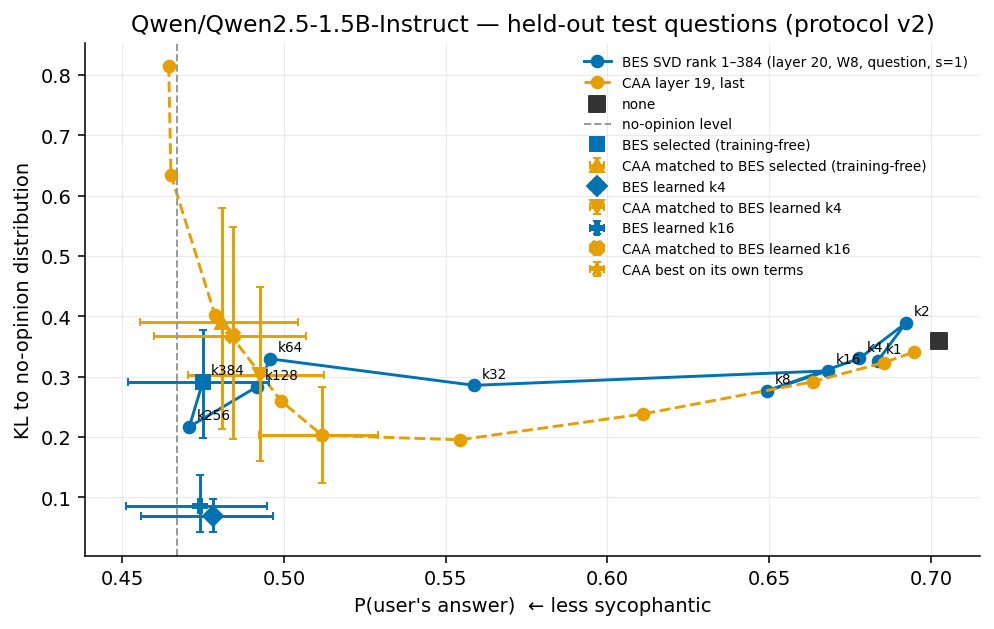

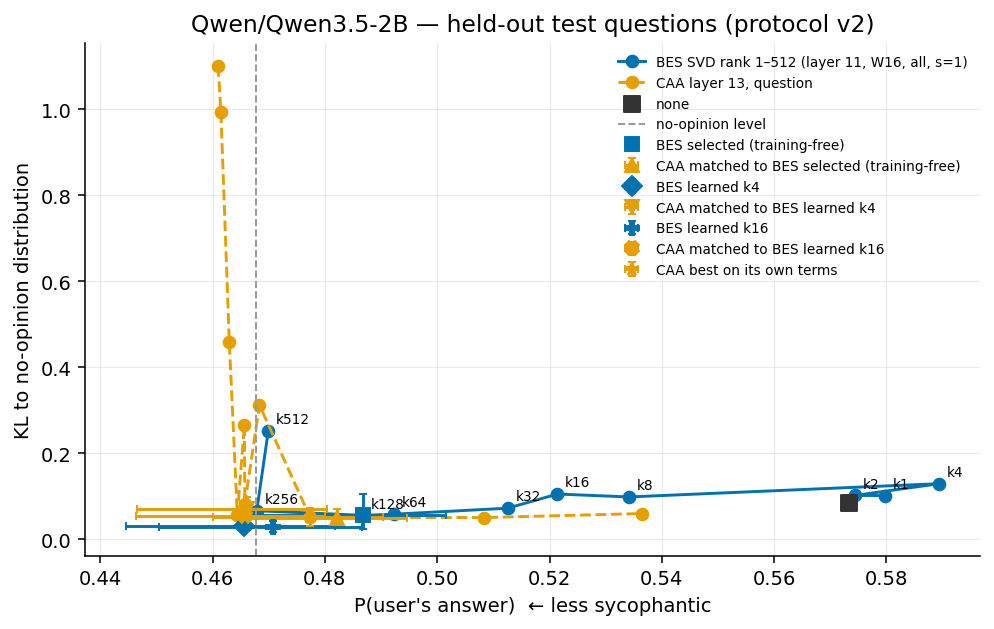

In [11]:
# Original Qwen (Qwen2.5-1.5B-Instruct) and current Qwen (Qwen3.5-2B)

summaries = {}
for spec in PART_A[:2]:
    summaries[spec["tag"]] = run_model(spec)
    if summaries[spec["tag"]] is not None:
        display(summaries[spec["tag"]].T)

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (12 outputs left out)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

 chat  is_v1_format         set  letter_mass  pad_mean_abs_diff  pad_max_abs_diff  pad_top_agree  mmlu_dev_acc  pad_unsafe  format_switched
 True          True fit_neutral        0.000              0.008             0.039            1.0           NaN       False             True
 True          True    mmlu_dev        0.000              0.008             0.046            1.0         0.562       False             True
False         False fit_neutral        0.990                NaN               NaN            NaN           NaN       False             True
False         False    mmlu_dev        0.999                NaN               NaN            NaN         0.672       False             True
  notebook-10 format puts only 0.00 on the letters: switching to chat=False
meta-llama/Llama-3.1-8B-Instruct | layers 32, d 4096, bf16, chat False, batch 32 | val: none 0.910 (KL 1.527), no-opinion 0.472 | fit items 999
  example prompt tail: 'ear people speak a language other than English in public

,0
model,llama31_8b
hf_name,meta-llama/Llama-3.1-8B-Instruct
layers,32
chat,False
format_switched,True
batch_size,32
bes_layer,20
bes_window,23
bes_span,all
rank_cap,1024


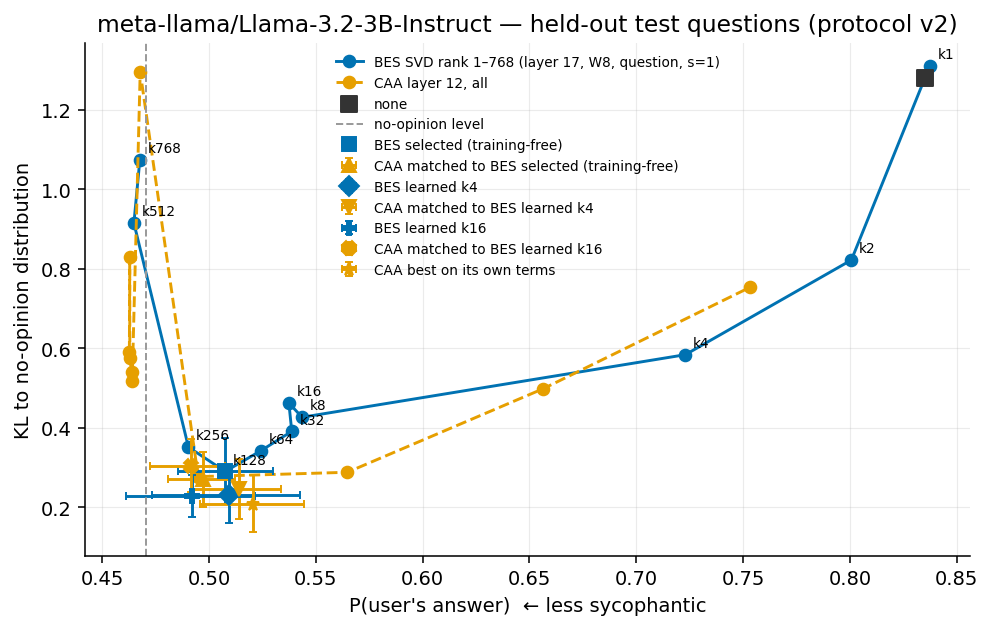

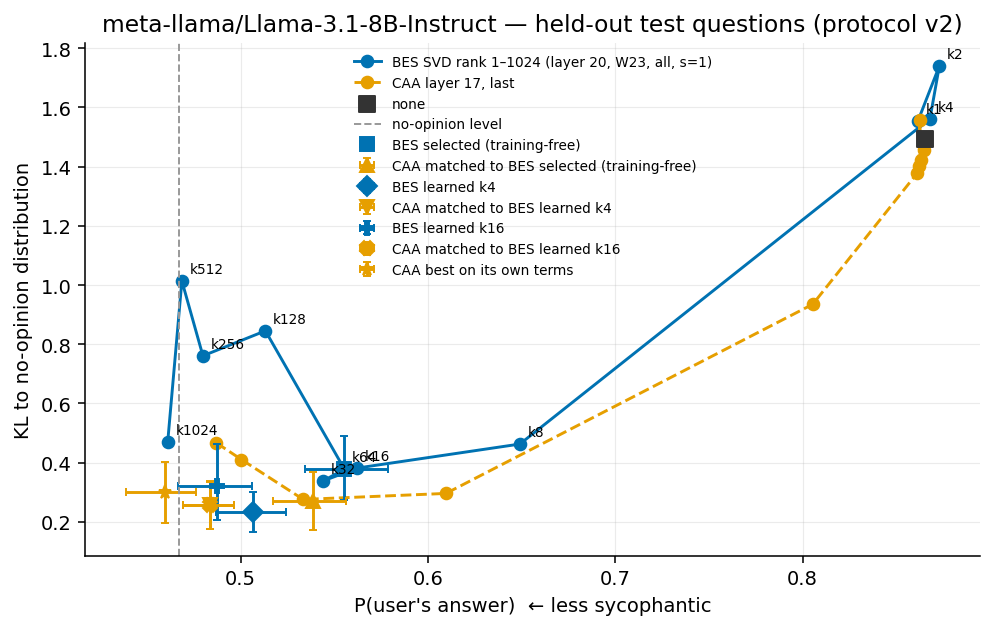

In [12]:
# Current Llama models (Llama-3.2-3B-Instruct, Llama-3.1-8B-Instruct; gated, each skipped with a message if access is missing)

for spec in PART_A[2:]:
    summaries[spec["tag"]] = run_model(spec)
    if summaries[spec["tag"]] is not None:
        display(summaries[spec["tag"]].T)

## 5. Part B — new models under the unchanged v2 protocol

The protocol was fixed before these models were run, so their results are an out-of-sample check on it.

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/79.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

 chat  is_v1_format         set  letter_mass  pad_mean_abs_diff  pad_max_abs_diff  pad_top_agree  mmlu_dev_acc  pad_unsafe  format_switched
 True          True fit_neutral        0.000              0.008             0.031          1.000           NaN       False             True
 True          True    mmlu_dev        0.000              0.009             0.042          0.953         0.438       False             True
False         False fit_neutral        0.952                NaN               NaN            NaN           NaN       False             True
False         False    mmlu_dev        0.983                NaN               NaN            NaN         0.672       False             True
  notebook-10 format puts only 0.00 on the letters: switching to chat=False
Qwen/Qwen3.5-9B | layers 32, d 4096, bf16, chat False, batch 32 | val: none 0.729 (KL 0.393), no-opinion 0.486 | fit items 999
  example prompt tail: 'ear people speak a language other than English in public places in your c

,0
model,qwen35_9b
hf_name,Qwen/Qwen3.5-9B
layers,32
chat,False
format_switched,True
batch_size,32
bes_layer,14
bes_window,16
bes_span,question
rank_cap,1024


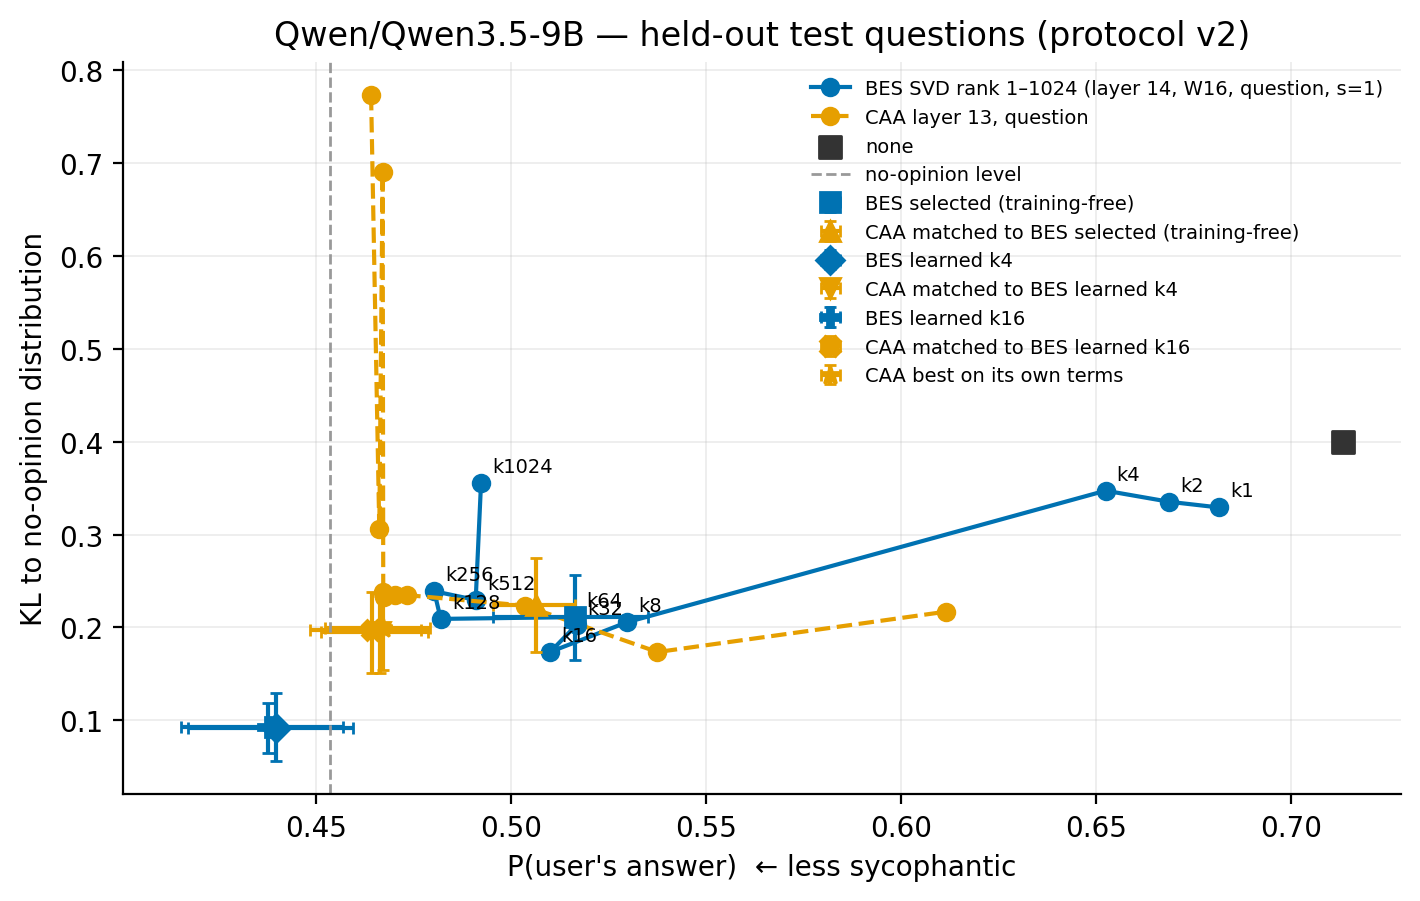

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

 chat  is_v1_format         set  letter_mass  pad_mean_abs_diff  pad_max_abs_diff  pad_top_agree  mmlu_dev_acc  pad_unsafe  format_switched
 True          True fit_neutral        0.137              0.004             0.035          1.000           NaN        True             True
 True          True    mmlu_dev        0.286              0.010             0.074          0.984         0.266        True             True
False         False fit_neutral        0.963                NaN               NaN            NaN           NaN        True             True
False         False    mmlu_dev        1.000                NaN               NaN            NaN         0.375        True             True
  batch padding changes the answers (mean change 0.010, top answer kept on 98%): scoring this model one prompt at a time
  notebook-10 format puts only 0.14 on the letters: switching to chat=False
meta-llama/Llama-2-7b-chat-hf | layers 32, d 4096, bf16, chat False, batch 1 | val: none 0.763 (KL 1.70

,0
model,llama2_7b
hf_name,meta-llama/Llama-2-7b-chat-hf
layers,32
chat,False
format_switched,True
batch_size,1
bes_layer,19
bes_window,27
bes_span,all
rank_cap,1024


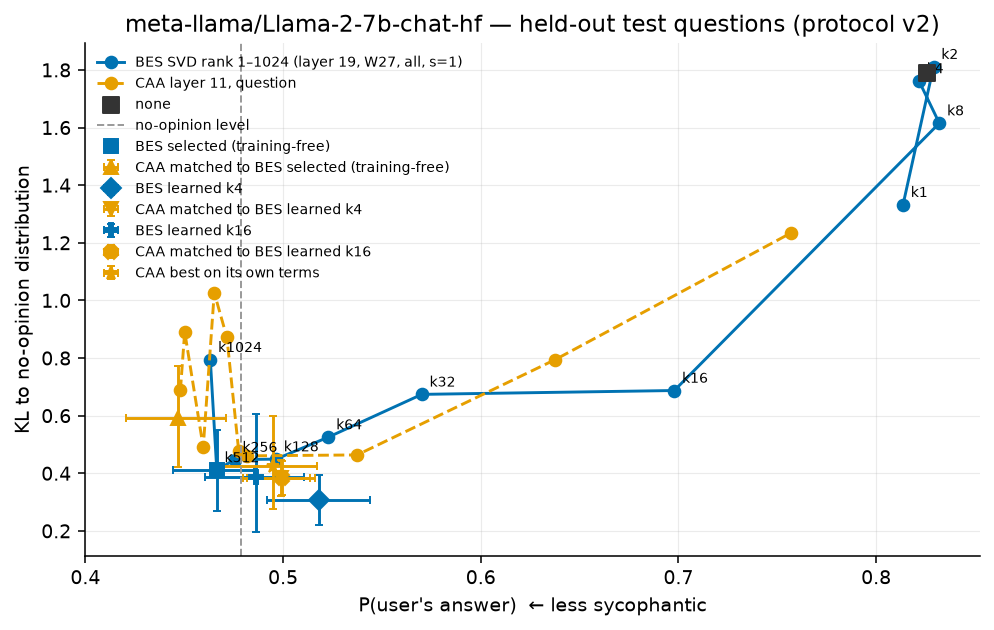

In [13]:
# Qwen3.5-9B and Llama-2-7B-Chat

for spec in PART_B:
    summaries[spec["tag"]] = run_model(spec)
    if summaries[spec["tag"]] is not None:
        display(summaries[spec["tag"]].T)

In [14]:
# Optional: Muse Glimmer 30B (off by default; set RUN_MUSE = True in section 1 to run it, expect 2+ hours)

if RUN_MUSE and not SMOKE:
    summaries[MUSE["tag"]] = run_model(MUSE)
    if summaries[MUSE["tag"]] is not None:
        display(summaries[MUSE["tag"]].T)
else:
    print(f"skipping optional {MUSE['name']} (set RUN_MUSE = True to run it)")

skipping optional meta-models/Muse-Glimmer-30B (set RUN_MUSE = True to run it)


## 6. Across models, and v1 against v2

Test sycophancy, KL, no-opinion KL and MMLU for BES and for CAA matched to it, model by model, then the same headline numbers from notebook 10 beside them.

In [15]:
# Summary table across models (test questions; MMLU drops in accuracy points)

summaries = {k: v for k, v in summaries.items() if v is not None}
summary = pd.concat(summaries.values(), ignore_index=True)
E.save(summary, f"{V}_summary")
cols = ["model", "chat", "batch_size", "bes_layer", "bes_window", "bes_span", "learned_layer", "cos_svd16_vs_caa", "none_syco", "no_opinion_syco"]
for key in ["svd"] + [f"k{K}" for K in LEARN_K]:
    if f"{key}_syco" in summary:
        summary[f"{key}_mmlu_drop"] = 100 * (summary.mmlu_none - summary[f"{key}_mmlu"])
        summary[f"{key}_caa_mmlu_drop"] = 100 * (summary.mmlu_none - summary[f"{key}_caa_mmlu"])
        cols += [f"{key}_desc" if key == "svd" else None, f"{key}_syco", f"{key}_caa_syco", f"{key}_kl", f"{key}_caa_kl", f"{key}_p_kl_vs_caa",
                 f"{key}_kl_neutral", f"{key}_caa_kl_neutral", f"{key}_mmlu_drop", f"{key}_caa_mmlu_drop"]
summary[[c for c in cols if c]].round(3).T

,0,1,2,3,4,5
model,qwen25_1p5b,qwen35_2b,llama32_3b,llama31_8b,qwen35_9b,llama2_7b
chat,False,False,False,False,False,False
batch_size,32,32,32,32,32,1
bes_layer,20,11,17,20,14,19
bes_window,8,16,8,23,16,27
bes_span,question,all,question,all,question,all
learned_layer,12,9,19,21,14,18
cos_svd16_vs_caa,0.284,0.321,0.248,0.167,0.211,0.164
none_syco,0.703,0.573,0.835,0.865,0.713,0.826
no_opinion_syco,0.467,0.468,0.471,0.467,0.454,0.479


In [16]:
# v1 (notebook 10) against v2 (this notebook) for every model run under both protocols

v1_path = E.RESULTS / "m10_summary.csv"
if v1_path.exists():
    v1 = pd.read_csv(v1_path)
    keys = [k for k in ["svd"] + [f"k{K}" for K in LEARN_K] if f"{k}_kl" in summary]
    rows = []
    for tag in summary.model:
        if tag not in set(v1.model):
            continue
        a_, b_ = v1.set_index("model").loc[tag], summary.set_index("model").loc[tag]
        for k in keys:
            if f"{k}_kl" not in v1:
                continue
            for proto, s in (("v1", a_), ("v2", b_)):
                rows.append({"model": tag, "bes": k, "protocol": proto, "bes_syco": s[f"{k}_syco"], "caa_syco": s[f"{k}_caa_syco"],
                             "bes_kl": s[f"{k}_kl"], "caa_kl": s[f"{k}_caa_kl"], "p_kl": s[f"{k}_p_kl_vs_caa"],
                             "bes_mmlu": s[f"{k}_mmlu"], "caa_mmlu": s[f"{k}_caa_mmlu"], "mmlu_none": s["mmlu_none"]})
    v1v2 = pd.DataFrame(rows)
    E.save(v1v2, f"{V}_v1_vs_v2")
    display(v1v2.round(3))
else:
    print("notebook 10 summary (results/m10_summary.csv) not found; run notebook 10 or copy its results to compare")

,model,bes,protocol,bes_syco,caa_syco,bes_kl,caa_kl,p_kl,bes_mmlu,caa_mmlu,mmlu_none
0,qwen25_1p5b,svd,v1,0.534,0.538,0.223,0.198,0.536,0.429,0.570,0.595
1,qwen25_1p5b,svd,v2,0.475,0.481,0.291,0.391,0.172,0.240,0.245,0.595
2,qwen25_1p5b,k4,v1,0.501,0.491,0.094,0.331,0.000,0.574,0.470,0.595
3,qwen25_1p5b,k4,v2,0.478,0.493,0.069,0.303,0.000,0.541,0.295,0.595
4,qwen25_1p5b,k16,v1,0.497,0.492,0.148,0.323,0.000,0.561,0.473,0.595
5,qwen25_1p5b,k16,v2,0.474,0.484,0.085,0.368,0.000,0.534,0.260,0.595
6,qwen35_2b,svd,v1,0.512,0.497,0.209,0.178,0.180,0.249,0.274,0.357
7,qwen35_2b,svd,v2,0.487,0.482,0.055,0.049,0.892,0.412,0.563,0.600
8,qwen35_2b,k4,v1,0.477,0.479,0.130,0.174,0.192,0.313,0.235,0.357
9,qwen35_2b,k4,v2,0.466,0.466,0.031,0.071,0.000,0.553,0.433,0.600


PosixPath('/home/crm4m/syco-erase/results/fig_m10b_rank_curves.png')

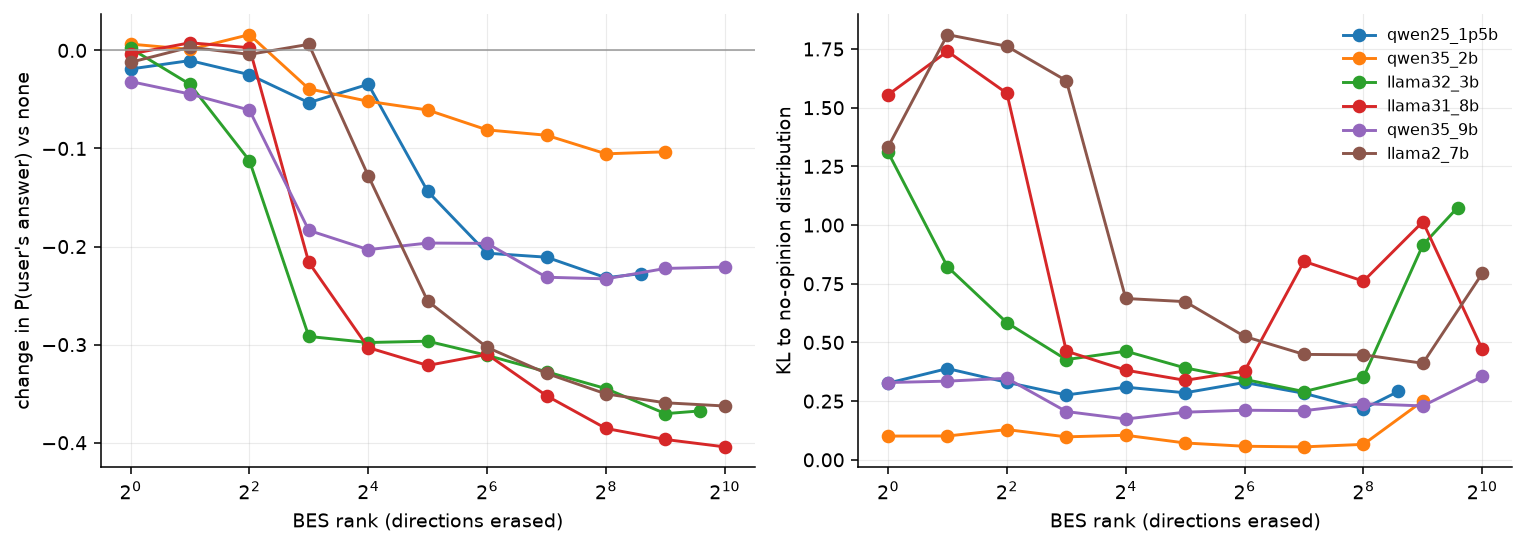

In [17]:
# Figure: BES rank curves under v2 (test sycophancy change and KL against rank) for every model

fig, axes = plots.subplots(1, 2, figsize=(11, 4))
for tag in summaries:
    full = pd.read_csv(E.RESULTS / f"{V}_{tag}_test.csv")
    d = full[full.kind == "rank curve"].copy()
    d["k"] = d.method.str.split().str[-1].astype(int)
    d = d.sort_values("k")
    none = full.set_index("method").loc["none"]
    axes[0].plot(d.k, d.syco - none.syco, "-o", label=tag)
    axes[1].plot(d.k, d.kl, "-o", label=tag)
for ax, yl in zip(axes, ("change in P(user's answer) vs none", "KL to no-opinion distribution")):
    ax.set_xscale("log", base=2); ax.set_xlabel("BES rank (directions erased)"); ax.set_ylabel(yl); plots.style(ax)
axes[0].axhline(0, color="#999999", lw=0.8); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); E.save_fig(fig, f"fig_{V}_rank_curves")